**Goal: flag orders likely to get a bad review early enough to act, such as by contacting the customer or escalating with the seller.**

The one rule: the model may only use information known before delivery. That means no is_late, days_late, delivery_days, review_score or review text. Using them is called data leakage. It would give a great-looking score and be useless in real life.

**Step 1: Setup and features**

In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_auc_score
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\Gafoo\OneDrive\Documents\GitHub\Olist-Customer-Experience-Analytics\notebooks\data\clean_orders.csv",
                 parse_dates=["order_purchase_timestamp"])
df.shape

(95560, 55)

In [3]:
# Known when the customer places the order
features = ["estimated_days", "freight_ratio", "items_price", "distance_km",
            "same_state", "n_items", "product_weight_g", "is_repeat_customer",
            "seller_prior_late_rate", "seller_prior_low_rate"]

# Version 2 adds one thing known when the seller ships
features_v2 = features + ["seller_handoff_days"]
len(features_v2)

11

**Step 2: Split by time and fill missing values**

In [4]:
train = df[df.order_purchase_timestamp < "2018-05-01"]
test  = df[df.order_purchase_timestamp >= "2018-05-01"]

medians = train[features_v2].median()                    # use TRAIN values only
X_train = train[features_v2].fillna(medians)
X_test = test[features_v2].fillna(medians)
y_train, y_test = train.low_review, test.low_review

print(len(train), len(test))
print("Bad-review rate: train", y_train.mean().round(3), "test", y_test.mean().round(3))

70318 25242
Bad-review rate: train 0.138 test 0.1


**Step 3: The dumb baseline**

In [5]:
print("If we always predict 'good review':")
print("  Accuracy:", round(1 - y_test.mean(), 3))
print("  Bad reviews caught: 0%")

If we always predict 'good review':
  Accuracy: 0.9
  Bad reviews caught: 0%


**Step 4: Model 1, logistic regression**

In [10]:
def report(name, y_true, pred, prob):
    print(f"\n{name}")
    print(confusion_matrix(y_true, pred))
    print("Precision: ", round(precision_score(y_true, pred), 3),
          "| Recall: ", round(recall_score(y_true, pred),3),
          "| ROC - AUC: ", round(roc_auc_score(y_true, prob),3))

# Version 1: purchase-time info only
scaler = StandardScaler().fit(X_train[features])
ir = LogisticRegression(class_weight= "balanced", max_iter=1000)
ir.fit(scaler.transform(X_train[features]), y_train)
prob_lr = ir.predict_proba(scaler.transform(X_test[features]))[:,1]
report("Logistic regression (purchase info)", y_test, (prob_ir > 0.5).astype(int), prob_ir)


Logistic regression (purchase info)
[[13603  9114]
 [ 1091  1434]]
Precision:  0.136 | Recall:  0.568 | ROC - AUC:  0.616


**Step 5: Model 2, decision tree**
A decision tree is a flowchart of yes/no questions. It’s the easiest model to explain.


Decision tree (purchase info)
[[13373  9344]
 [ 1046  1479]]
Precision:  0.137 | Recall:  0.586 | ROC - AUC:  0.612


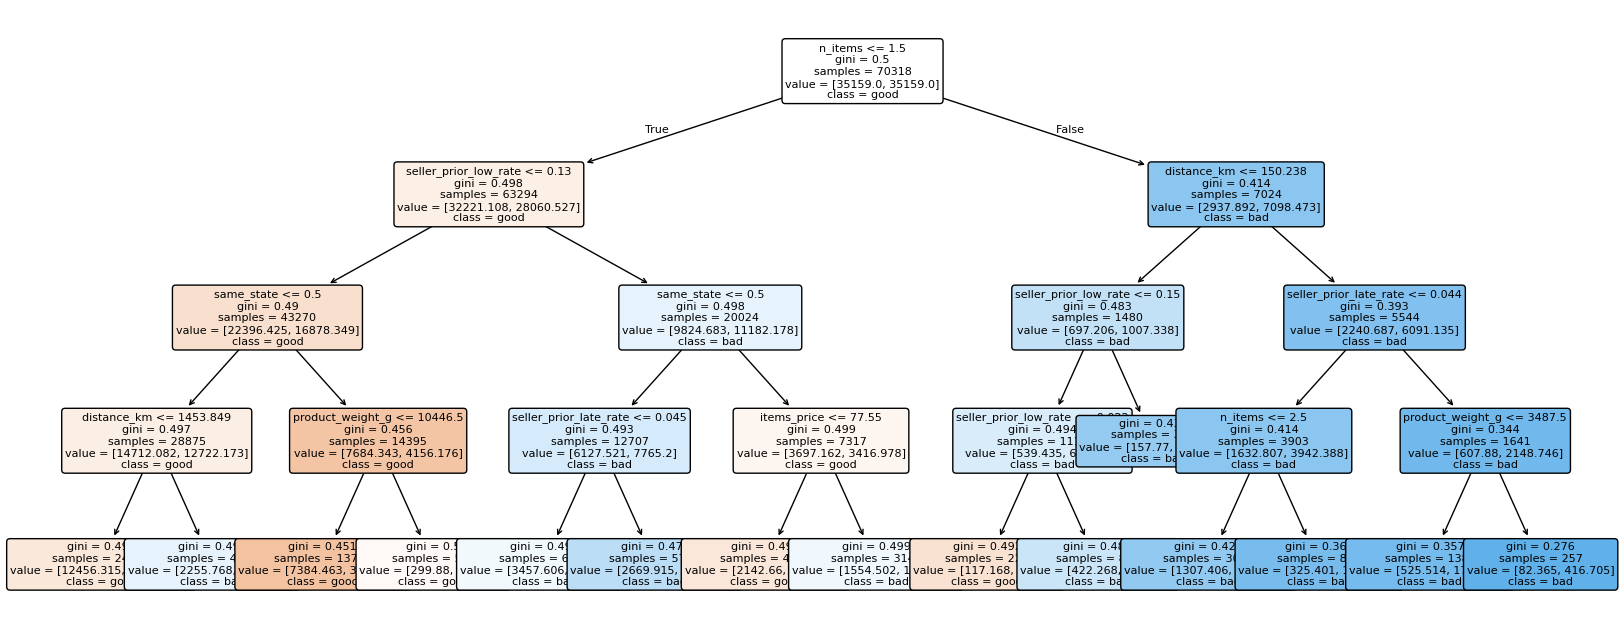

In [7]:
tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=200,
                              class_weight="balanced", random_state=42)
tree.fit(X_train[features], y_train)
prob_tree = tree.predict_proba(X_test[features])[:, 1]
report("Decision tree (purchase info)", y_test, tree.predict(X_test[features]), prob_tree)

plt.figure(figsize=(20, 8))
plot_tree(tree, feature_names=features, class_names=["good", "bad"],
          filled=True, rounded=True, fontsize=8)
plt.savefig("images/09_decision_tree.png", dpi=150, bbox_inches="tight")

max_depth=4 keeps the tree small enough to read. Without it, the tree memorizes the training data (overfitting).

Say it like this: “A decision tree asks a series of yes/no questions, like ‘is the promised delivery longer than 25 days?’, and each answer leads to a prediction. I limited its depth to 4 so it stays readable and doesn’t memorize the training data.”

**Step 6: Does shipping info help? (Version 2)**

In [8]:
scaler2 = StandardScaler().fit(X_train)
lr2 = LogisticRegression(class_weight="balanced", max_iter=1000)
lr2.fit(scaler2.transform(X_train), y_train)
prob_lr2 = lr2.predict_proba(scaler2.transform(X_test))[:, 1]
report("Logistic regression (+ shipping info)", y_test, (prob_lr2 > 0.5).astype(int), prob_lr2)


Logistic regression (+ shipping info)
[[15567  7150]
 [ 1168  1357]]
Precision:  0.16 | Recall:  0.537 | ROC - AUC:  0.645


Say it like this: “Version 1 predicts at purchase time. Version 2 adds seller handoff time, which is known once the seller ships, so it can update the risk a few days later. I compared both to see how much the extra information helps.”

**Step 7: The business table (most important)**

In [11]:
def top_k(prob, y, ks=(0.05, 0.10, 0.20)):
    order = np.argsort(-prob)
    rows = []
    for k in ks:
        n = int(len(prob) * k)
        flagged = y.values[order[:n]]
        rows.append({"flag riskiest": f"{k:.0%}",
                     "bad reviews caught": f"{flagged.sum() / y.sum():.0%}",
                     "times better than random": round(flagged.mean() / y.mean(), 1)})
    return pd.DataFrame(rows)

print(top_k(prob_lr, y_test))
print(top_k(prob_lr2, y_test))

  flag riskiest bad reviews caught  times better than random
0            5%                12%                       2.5
1           10%                24%                       2.4
2           20%                37%                       1.8
  flag riskiest bad reviews caught  times better than random
0            5%                14%                       2.9
1           10%                25%                       2.5
2           20%                39%                       2.0


Say it like this: “If the support team contacts only the riskiest 10% of orders, we catch X% of future bad reviews, which is Y times better than picking at random.”

**Step 8: What drives the predictions?**

n_items                   0.559
seller_prior_low_rate     0.169
same_state                0.148
distance_km               0.061
seller_prior_late_rate    0.040
dtype: float64


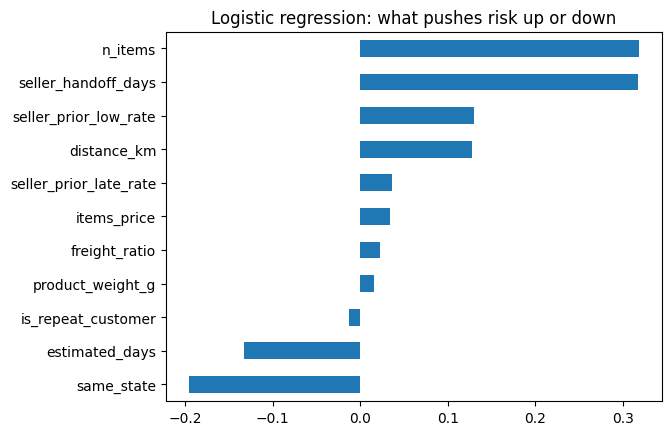

In [ ]:
coef = pd.Series(lr2.coef_[0], index=features_v2).sort_values()
coef.plot(kind="barh", title="Logistic regression: what pushes risk up or down")
plt.savefig("images/10_coefficients.png", dpi=150, bbox_inches="tight")

print(pd.Series(tree.feature_importances_, index=features)
        .sort_values(ascending=False).head(5).round(3))


## Model summary

**Goal:** flag orders likely to get a 1-2 star review before delivery, so the team can step in.

**Rule:** only information known at purchase or shipping time. No delivery outcome and no review data, to avoid data leakage.

**Method:** trained on orders before May 2018 (70,318 orders) and tested on May-Aug 2018 (25,242 orders), like predicting the future from the past. Missing values were filled with medians computed on the training set only.

**Models:** logistic regression and a decision tree (depth 4), compared with an "always good" baseline.

| Model | Precision | Recall | ROC-AUC |
|---|---|---|---|
| Baseline (always "good") | - | 0% | 0.500 |
| Logistic regression (purchase info) | 0.136 | 0.568 | 0.616 |
| Decision tree (purchase info) | 0.137 | 0.586 | 0.612 |
| Logistic regression (+ shipping info) | 0.160 | 0.537 | 0.645 |

Accuracy is not used to judge the models: the baseline already scores 90% because only 10% of test orders get bad reviews.

**Result:** flagging the riskiest 10% of orders catches **24%** of bad reviews, **2.4x** better than random. Adding shipping info improves this to **25%** (2.5x), and the AUC rises from 0.616 to 0.645.

| Flag riskiest | Caught (purchase info) | Lift | Caught (+ shipping info) | Lift |
|---|---|---|---|---|
| 5% | 12% | 2.5x | 14% | 2.9x |
| 10% | 24% | 2.4x | 25% | 2.5x |
| 20% | 37% | 1.8x | 39% | 2.0x |

**Top drivers:**
- **Raise risk:** more items in the order (`n_items`), slow seller handoff (`seller_handoff_days`), sellers with a history of low reviews (`seller_prior_low_rate`), and longer shipping distance (`distance_km`).
- **Lower risk:** buyer and seller in the same state (`same_state`) and a longer estimated delivery window (`estimated_days`).
- The decision tree agrees: `n_items` (56%), `seller_prior_low_rate` (17%) and `same_state` (15%) are its most important features.

**Limits:**
- Reviews also depend on things we can't see (product quality, customer mood), so the model helps prioritize orders but cannot predict perfectly (AUC about 0.65).
- The drivers show association, not cause.
- The bad-review rate fell from 13.8% (train) to 10.0% (test), so the model should be monitored and retrained over time.
- At the default 0.5 threshold the model flags 34-43% of orders, which is too many for a team to act on. Use the top-k ranking instead.